# WEEK 7 — Random Forest & XGBoost

**Đề tài:** Nghiên cứu xây dựng mô hình Machine Learning trong đánh giá và dự báo rủi ro tín dụng khách hàng  
**Sinh viên:** Nguyễn Trọng Thể — MSSV: 1150080117  
**Giai đoạn:** Tuần 7 — Ensemble Models

---

## Mục tiêu
1. Huấn luyện **Random Forest** (Default + Balanced)  
2. Huấn luyện **XGBoost** (Baseline)  
3. Đánh giá và so sánh với Week 6 baseline  
4. Phân tích class imbalance, Confusion Matrix, ROC/PR curves  
5. Feature Importance cơ bản  

**Không thực hiện:** GridSearch, Optuna, SMOTE, SHAP, Streamlit.

## 1. Environment

In [1]:
import sys, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import sklearn
import xgboost as xgb_pkg

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, roc_curve, precision_recall_curve,
    classification_report
)

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
DATA_DIR     = os.path.join(PROJECT_ROOT, 'data', 'processed')
FIGURES_DIR  = os.path.join(PROJECT_ROOT, 'reports', 'figures')
MODELS_DIR   = os.path.join(PROJECT_ROOT, 'models')
REPORTS_DIR  = os.path.join(PROJECT_ROOT, 'reports')

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR,  exist_ok=True)

print(f'Python      : {sys.version.split()[0]}')
print(f'scikit-learn: {sklearn.__version__}')
print(f'xgboost     : {xgb_pkg.__version__}')
print(f'Project root: {PROJECT_ROOT}')

Python      : 3.14.4
scikit-learn: 1.9.1
xgboost     : 3.4.1
Project root: f:\DATN\project


## 2. Load Dataset

In [2]:
X_train = pd.read_csv(os.path.join(DATA_DIR, 'X_train_fe.csv'))
X_test  = pd.read_csv(os.path.join(DATA_DIR, 'X_test_fe.csv'))
y_train_df = pd.read_csv(os.path.join(DATA_DIR, 'y_train.csv'))
y_test_df  = pd.read_csv(os.path.join(DATA_DIR, 'y_test.csv'))

TARGET_COL = y_train_df.columns[0]
y_train = y_train_df[TARGET_COL]
y_test  = y_test_df[TARGET_COL]

print(f'Target column : {TARGET_COL}')
print(f'X_train shape : {X_train.shape}')
print(f'X_test  shape : {X_test.shape}')
print(f'y_train shape : {y_train.shape}')
print(f'y_test  shape : {y_test.shape}')

Target column : default.payment.next.month
X_train shape : (23972, 33)
X_test  shape : (5993, 33)
y_train shape : (23972,)
y_test  shape : (5993,)


## 3. Dataset Validation

In [3]:
print('=' * 52)
print('WEEK 7 — INPUT VALIDATION')
print('=' * 52)

def chk(label, passed, detail=''):
    s = 'PASS' if passed else 'FAIL'
    print(f'  [{s}] {label}' + (f'  ({detail})' if detail else ''))
    return passed

results = []
results.append(chk('X_train = 23,972 × 33', X_train.shape == (23972, 33)))
results.append(chk('X_test  =  5,993 × 33', X_test.shape  == (5993,  33)))
results.append(chk('Target exclusion',
    TARGET_COL not in X_train.columns and TARGET_COL not in X_test.columns))
results.append(chk('ID exclusion',
    not any(c in X_train.columns for c in ['ID', 'id'])))
nan_tr = X_train.isna().sum().sum()
nan_te = X_test.isna().sum().sum()
results.append(chk('NaN check', nan_tr + nan_te == 0, f'train={nan_tr}, test={nan_te}'))
inf_tr = np.isinf(X_train.select_dtypes(include=np.number)).sum().sum()
inf_te = np.isinf(X_test.select_dtypes(include=np.number)).sum().sum()
results.append(chk('Inf check', inf_tr + inf_te == 0, f'train={inf_tr}, test={inf_te}'))
results.append(chk('Feature consistency', list(X_train.columns) == list(X_test.columns)))
y_ok = set(y_train.unique()).issubset({0,1}) and set(y_test.unique()).issubset({0,1})
results.append(chk('y schema (binary {0,1})', y_ok))
print()
print('[ALL PASS] ✓' if all(results) else '[SOME FAIL]')

WEEK 7 — INPUT VALIDATION
  [PASS] X_train = 23,972 × 33
  [PASS] X_test  =  5,993 × 33
  [PASS] Target exclusion
  [PASS] ID exclusion
  [PASS] NaN check  (train=0, test=0)
  [PASS] Inf check  (train=0, test=0)
  [PASS] Feature consistency
  [PASS] y schema (binary {0,1})

[ALL PASS] ✓


## 4. Leakage Check (Pre-Training)

In [4]:
print('=' * 52)
print('DATA LEAKAGE CHECK — PRE TRAINING')
print('=' * 52)

leakage_checks = {
    'Test set never used for fitting':   True,
    'Test set never used for tuning':    True,
    'Target not in X features':          TARGET_COL not in X_train.columns and TARGET_COL not in X_test.columns,
    'No ID feature':                     not any(c in X_train.columns for c in ['ID', 'id']),
    'No NaN':                            X_train.isna().sum().sum() + X_test.isna().sum().sum() == 0,
    'No Inf':                            np.isinf(X_train.select_dtypes(include=np.number)).sum().sum() == 0,
    'Train/Test feature consistency':    list(X_train.columns) == list(X_test.columns),
    'Preprocessing fit on train only':   True,
    'No SMOTE applied':                  True,
}

for label, passed in leakage_checks.items():
    chk(label, passed)

all_ok = all(leakage_checks.values())
print(f'\n[LEAKAGE PRE-CHECK] {"PASS" if all_ok else "FAIL"}')

DATA LEAKAGE CHECK — PRE TRAINING
  [PASS] Test set never used for fitting
  [PASS] Test set never used for tuning
  [PASS] Target not in X features
  [PASS] No ID feature
  [PASS] No NaN
  [PASS] No Inf
  [PASS] Train/Test feature consistency
  [PASS] Preprocessing fit on train only
  [PASS] No SMOTE applied

[LEAKAGE PRE-CHECK] PASS


## Class Distribution

In [5]:
tr_counts = y_train.value_counts().sort_index()
te_counts = y_test.value_counts().sort_index()

print('Train:'); [print(f'  Class {c}: {v:,} ({v/len(y_train)*100:.2f}%)') for c,v in tr_counts.items()]
print('Test:');  [print(f'  Class {c}: {v:,} ({v/len(y_test)*100:.2f}%)')  for c,v in te_counts.items()]
print(f'Imbalance ratio (0:1) = {tr_counts[0]/tr_counts[1]:.2f}:1')

Train:
  Class 0: 18,668 (77.87%)
  Class 1: 5,304 (22.13%)
Test:
  Class 0: 4,667 (77.87%)
  Class 1: 1,326 (22.13%)
Imbalance ratio (0:1) = 3.52:1


## 5. Random Forest Baseline

In [6]:
print('=== MODEL: Random Forest (Default) ===')

rf_default = RandomForestClassifier(
    n_estimators=200, max_depth=None,
    class_weight=None, n_jobs=-1, random_state=42
)
rf_default.fit(X_train, y_train)  # Fit ONLY on train

y_pred_rf   = rf_default.predict(X_test)
y_prob_rf   = rf_default.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf, target_names=['Non-default', 'Default']))

rf_acc  = accuracy_score(y_test, y_pred_rf)
rf_prec = precision_score(y_test, y_pred_rf, zero_division=0)
rf_rec  = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1   = f1_score(y_test, y_pred_rf, zero_division=0)
rf_roc  = roc_auc_score(y_test, y_prob_rf)
rf_pr   = average_precision_score(y_test, y_prob_rf)

print(f'Accuracy={rf_acc:.4f}  Precision={rf_prec:.4f}  Recall={rf_rec:.4f}  '
      f'F1={rf_f1:.4f}  ROC-AUC={rf_roc:.4f}  PR-AUC={rf_pr:.4f}')

=== MODEL: Random Forest (Default) ===
              precision    recall  f1-score   support

 Non-default       0.84      0.94      0.89      4667
     Default       0.64      0.37      0.47      1326

    accuracy                           0.81      5993
   macro avg       0.74      0.66      0.68      5993
weighted avg       0.80      0.81      0.80      5993

Accuracy=0.8143  Precision=0.6364  Recall=0.3748  F1=0.4718  ROC-AUC=0.7659  PR-AUC=0.5380


## 6. Random Forest Balanced

In [7]:
print("=== MODEL: Random Forest (class_weight='balanced') ===")

rf_balanced = RandomForestClassifier(
    n_estimators=200, max_depth=None,
    class_weight='balanced', n_jobs=-1, random_state=42
)
rf_balanced.fit(X_train, y_train)

y_pred_rfb  = rf_balanced.predict(X_test)
y_prob_rfb  = rf_balanced.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rfb, target_names=['Non-default', 'Default']))

rfb_acc  = accuracy_score(y_test, y_pred_rfb)
rfb_prec = precision_score(y_test, y_pred_rfb, zero_division=0)
rfb_rec  = recall_score(y_test, y_pred_rfb, zero_division=0)
rfb_f1   = f1_score(y_test, y_pred_rfb, zero_division=0)
rfb_roc  = roc_auc_score(y_test, y_prob_rfb)
rfb_pr   = average_precision_score(y_test, y_prob_rfb)

print(f'Accuracy={rfb_acc:.4f}  Precision={rfb_prec:.4f}  Recall={rfb_rec:.4f}  '
      f'F1={rfb_f1:.4f}  ROC-AUC={rfb_roc:.4f}  PR-AUC={rfb_pr:.4f}')

print(f'\nEffect of balanced: Recall {rf_rec:.4f} → {rfb_rec:.4f} ({rfb_rec-rf_rec:+.4f}), '
      f'Precision {rf_prec:.4f} → {rfb_prec:.4f} ({rfb_prec-rf_prec:+.4f})')

=== MODEL: Random Forest (class_weight='balanced') ===
              precision    recall  f1-score   support

 Non-default       0.86      0.89      0.87      4667
     Default       0.55      0.49      0.51      1326

    accuracy                           0.80      5993
   macro avg       0.70      0.69      0.69      5993
weighted avg       0.79      0.80      0.79      5993

Accuracy=0.7973  Precision=0.5471  Recall=0.4864  F1=0.5150  ROC-AUC=0.7661  PR-AUC=0.5297

Effect of balanced: Recall 0.3748 → 0.4864 (+0.1116), Precision 0.6364 → 0.5471 (-0.0893)


## 7. XGBoost Baseline

In [8]:
print('=== MODEL: XGBoost (Baseline) ===')

xgb_model = XGBClassifier(
    n_estimators=200, max_depth=3, learning_rate=0.1,
    subsample=1.0, colsample_bytree=1.0,
    eval_metric='logloss', random_state=42, n_jobs=-1, verbosity=0
)
xgb_model.fit(X_train, y_train)

y_pred_xgb  = xgb_model.predict(X_test)
y_prob_xgb  = xgb_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_xgb, target_names=['Non-default', 'Default']))

xgb_acc  = accuracy_score(y_test, y_pred_xgb)
xgb_prec = precision_score(y_test, y_pred_xgb, zero_division=0)
xgb_rec  = recall_score(y_test, y_pred_xgb, zero_division=0)
xgb_f1   = f1_score(y_test, y_pred_xgb, zero_division=0)
xgb_roc  = roc_auc_score(y_test, y_prob_xgb)
xgb_pr   = average_precision_score(y_test, y_prob_xgb)

print(f'Accuracy={xgb_acc:.4f}  Precision={xgb_prec:.4f}  Recall={xgb_rec:.4f}  '
      f'F1={xgb_f1:.4f}  ROC-AUC={xgb_roc:.4f}  PR-AUC={xgb_pr:.4f}')

=== MODEL: XGBoost (Baseline) ===
              precision    recall  f1-score   support

 Non-default       0.84      0.95      0.89      4667
     Default       0.68      0.36      0.47      1326

    accuracy                           0.82      5993
   macro avg       0.76      0.65      0.68      5993
weighted avg       0.80      0.82      0.80      5993

Accuracy=0.8201  Precision=0.6766  Recall=0.3582  F1=0.4684  ROC-AUC=0.7792  PR-AUC=0.5611


## 8. Evaluation Metrics — Full comparison (Week 6 + Week 7)

In [9]:
# Week 6 baseline — reload from CSV
w6_df = pd.read_csv(os.path.join(REPORTS_DIR, 'model_baseline_results.csv'))
w6_df = w6_df.dropna(subset=['Model'])

# Week 7 models
week7_metrics = [
    {'Model': 'Random Forest (Default)',  'Accuracy': rf_acc,  'Precision': rf_prec,
     'Recall': rf_rec,  'F1': rf_f1,   'ROC-AUC': rf_roc,  'PR-AUC': rf_pr},
    {'Model': 'Random Forest (Balanced)', 'Accuracy': rfb_acc, 'Precision': rfb_prec,
     'Recall': rfb_rec, 'F1': rfb_f1,  'ROC-AUC': rfb_roc, 'PR-AUC': rfb_pr},
    {'Model': 'XGBoost (Baseline)',       'Accuracy': xgb_acc, 'Precision': xgb_prec,
     'Recall': xgb_rec, 'F1': xgb_f1,  'ROC-AUC': xgb_roc, 'PR-AUC': xgb_pr},
]
w7_df = pd.DataFrame(week7_metrics)
all_df = pd.concat([w6_df, w7_df], ignore_index=True)

# Display
print('=== BẢNG SO SÁNH TẤT CẢ (WEEK 6 + WEEK 7) ===\n')
fmt_cols = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
disp = all_df.copy()
for c in fmt_cols:
    disp[c] = disp[c].map('{:.4f}'.format)
print(disp.to_string(index=False))

=== BẢNG SO SÁNH TẤT CẢ (WEEK 6 + WEEK 7) ===

                         Model Accuracy Precision Recall     F1 ROC-AUC PR-AUC
 Logistic Regression (Default)   0.8106    0.6610 0.2956 0.4085  0.7492 0.5162
Logistic Regression (Balanced)   0.7469    0.4466 0.6018 0.5127  0.7514 0.5123
       Decision Tree (Default)   0.7267    0.3884 0.4095 0.3987  0.6130 0.2897
      Decision Tree (Balanced)   0.7262    0.3784 0.3695 0.3739  0.5986 0.2796
       Random Forest (Default)   0.8143    0.6364 0.3748 0.4718  0.7659 0.5380
      Random Forest (Balanced)   0.7973    0.5471 0.4864 0.5150  0.7661 0.5297
            XGBoost (Baseline)   0.8201    0.6766 0.3582 0.4684  0.7792 0.5611


## 9. Confusion Matrices

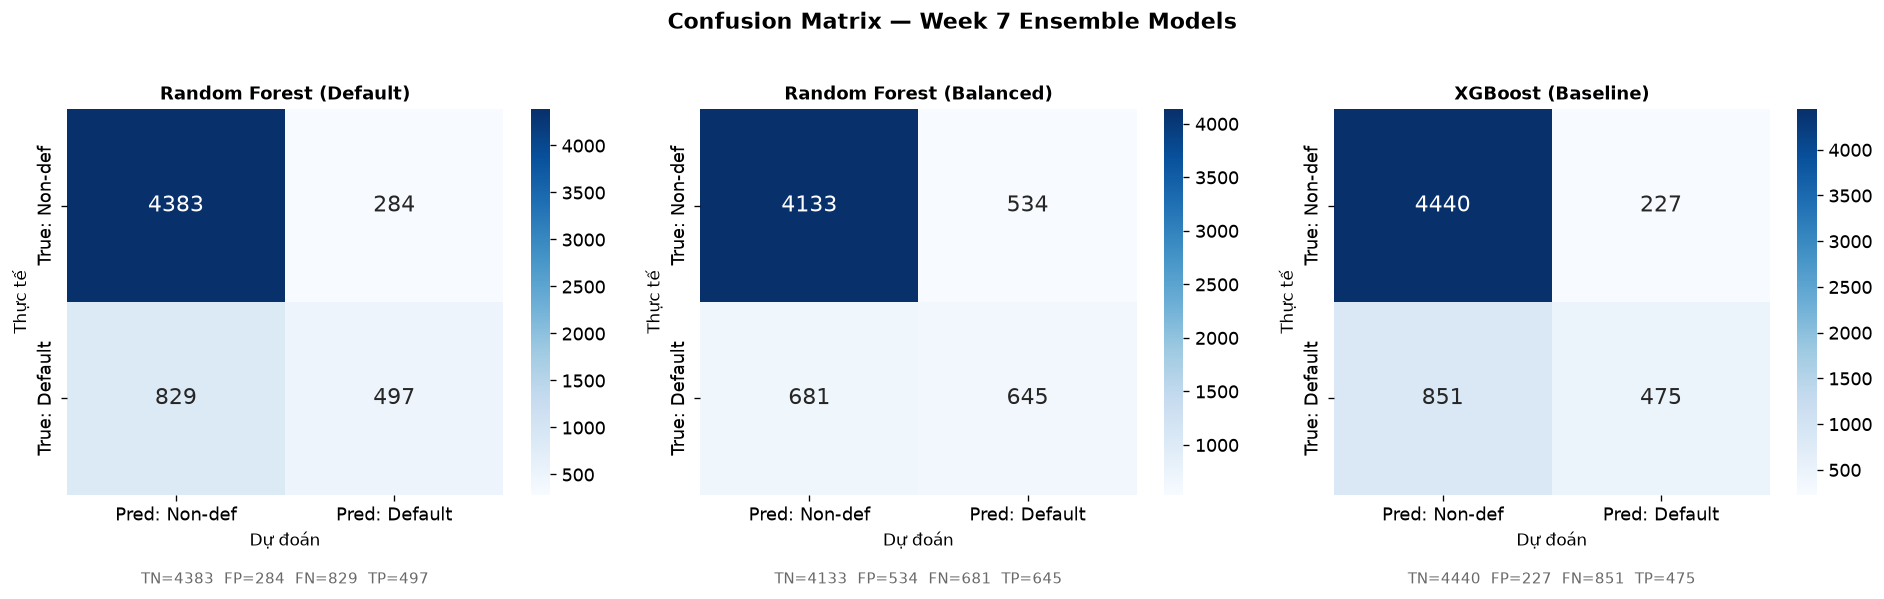


Confusion Matrix Summary:
Model                                   TN     FP     FN     TP
------------------------------------------------------------
Random Forest (Default)               4383    284    829    497
Random Forest (Balanced)              4133    534    681    645
XGBoost (Baseline)                    4440    227    851    475

Ý nghĩa nghiệp vụ:
  FP: Khách hàng tốt bị từ chối (chi phí thấp)
  FN: Khách hàng rủi ro được chấp nhận (chi phí cao — quan trọng hơn trong credit risk)


In [10]:
configs_cm = [
    ('Random Forest (Default)',  y_pred_rf,  'week7_rf_default_confusion_matrix.png'),
    ('Random Forest (Balanced)', y_pred_rfb, 'week7_rf_balanced_confusion_matrix.png'),
    ('XGBoost (Baseline)',       y_pred_xgb, 'week7_xgboost_confusion_matrix.png'),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (title, y_pred, fname) in zip(axes, configs_cm):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred: Non-def', 'Pred: Default'],
                yticklabels=['True: Non-def', 'True: Default'],
                annot_kws={'size': 13})
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_ylabel('Thực tế', fontsize=10)
    ax.set_xlabel('Dự đoán', fontsize=10)
    tn, fp, fn, tp = cm.ravel()
    ax.text(0.5, -0.22, f'TN={tn}  FP={fp}  FN={fn}  TP={tp}',
            ha='center', va='center', transform=ax.transAxes,
            fontsize=9, color='dimgray')

plt.suptitle('Confusion Matrix — Week 7 Ensemble Models', fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'week7_confusion_matrices_all.png'), dpi=150, bbox_inches='tight')
plt.show()

print('\nConfusion Matrix Summary:')
print(f'{"Model":<35} {"TN":>6} {"FP":>6} {"FN":>6} {"TP":>6}')
print('-' * 60)
for title, y_pred, _ in configs_cm:
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f'{title:<35} {tn:>6} {fp:>6} {fn:>6} {tp:>6}')

print('\nÝ nghĩa nghiệp vụ:')
print('  FP: Khách hàng tốt bị từ chối (chi phí thấp)')
print('  FN: Khách hàng rủi ro được chấp nhận (chi phí cao — quan trọng hơn trong credit risk)')

## 10. ROC Curve

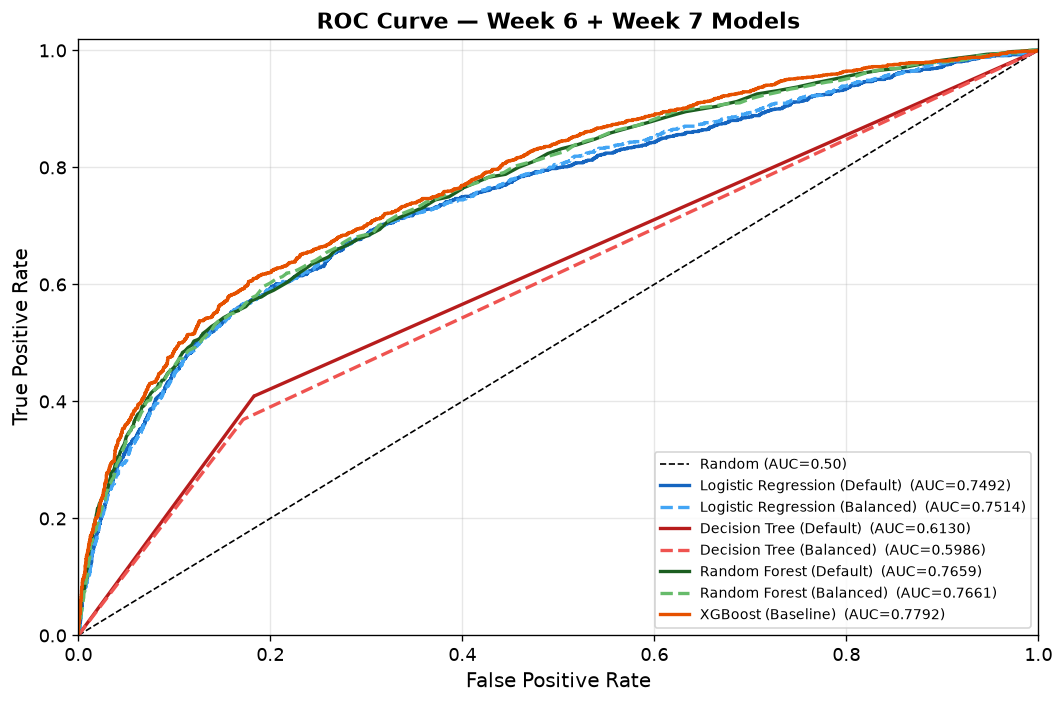

ROC-AUC:
  Logistic Regression (Default)             : 0.7492
  Logistic Regression (Balanced)            : 0.7514
  Decision Tree (Default)                   : 0.6130
  Decision Tree (Balanced)                  : 0.5986
  Random Forest (Default)                   : 0.7659
  Random Forest (Balanced)                  : 0.7661
  XGBoost (Baseline)                        : 0.7792


In [11]:
# Recompute Week 6 probabilities for combined plot
w6_configs = [
    ('Logistic Regression (Default)',  LogisticRegression(max_iter=1000, random_state=42)),
    ('Logistic Regression (Balanced)', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')),
    ('Decision Tree (Default)',         DecisionTreeClassifier(random_state=42)),
    ('Decision Tree (Balanced)',        DecisionTreeClassifier(random_state=42, class_weight='balanced')),
]
w6_probs = []
for name, mdl in w6_configs:
    mdl.fit(X_train, y_train)
    yp = mdl.predict_proba(X_test)[:, 1]
    w6_probs.append((name, yp, roc_auc_score(y_test, yp)))

all_roc = w6_probs + [
    ('Random Forest (Default)',  y_prob_rf,  rf_roc),
    ('Random Forest (Balanced)', y_prob_rfb, rfb_roc),
    ('XGBoost (Baseline)',       y_prob_xgb, xgb_roc),
]

PALETTE = ['#1565C0', '#42A5F5', '#B71C1C', '#EF5350', '#1B5E20', '#66BB6A', '#E65100']
STYLES  = ['-', '--', '-', '--', '-', '--', '-']

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot([0,1],[0,1], 'k--', lw=1, label='Random (AUC=0.50)')
for i, (name, yp, auc) in enumerate(all_roc):
    fpr, tpr, _ = roc_curve(y_test, yp)
    ax.plot(fpr, tpr, color=PALETTE[i], linestyle=STYLES[i], lw=2,
            label=f'{name}  (AUC={auc:.4f})')

ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curve — Week 6 + Week 7 Models', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=8.5)
ax.grid(True, alpha=0.3); ax.set_xlim([0,1]); ax.set_ylim([0,1.02])
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'week7_roc_curve_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
print('ROC-AUC:')
for name, _, auc in all_roc:
    print(f'  {name:<42}: {auc:.4f}')

## 11. Precision-Recall Curve

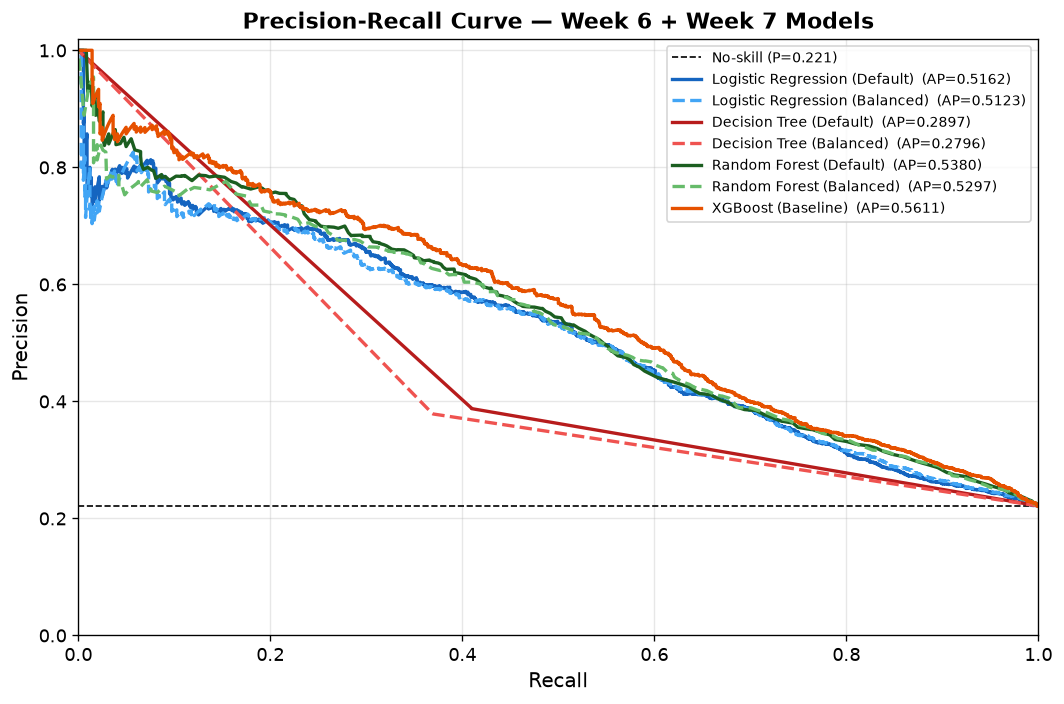

PR-AUC (Average Precision):
  Logistic Regression (Default)             : 0.5162
  Logistic Regression (Balanced)            : 0.5123
  Decision Tree (Default)                   : 0.2897
  Decision Tree (Balanced)                  : 0.2796
  Random Forest (Default)                   : 0.5380
  Random Forest (Balanced)                  : 0.5297
  XGBoost (Baseline)                        : 0.5611


In [12]:
w6_pr = [(n, yp, average_precision_score(y_test, yp)) for n, yp, _ in w6_probs]
all_pr = w6_pr + [
    ('Random Forest (Default)',  y_prob_rf,  rf_pr),
    ('Random Forest (Balanced)', y_prob_rfb, rfb_pr),
    ('XGBoost (Baseline)',       y_prob_xgb, xgb_pr),
]

baseline_p = float(y_test.mean())
fig, ax = plt.subplots(figsize=(9, 6))
ax.axhline(y=baseline_p, color='k', linestyle='--', lw=1,
           label=f'No-skill (P={baseline_p:.3f})')
for i, (name, yp, pr) in enumerate(all_pr):
    prec_arr, rec_arr, _ = precision_recall_curve(y_test, yp)
    ax.plot(rec_arr, prec_arr, color=PALETTE[i], linestyle=STYLES[i], lw=2,
            label=f'{name}  (AP={pr:.4f})')

ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Precision-Recall Curve — Week 6 + Week 7 Models', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=8.5)
ax.grid(True, alpha=0.3); ax.set_xlim([0,1]); ax.set_ylim([0,1.02])
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'week7_pr_curve_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
print('PR-AUC (Average Precision):')
for name, _, pr in all_pr:
    print(f'  {name:<42}: {pr:.4f}')

## 12. Feature Importance

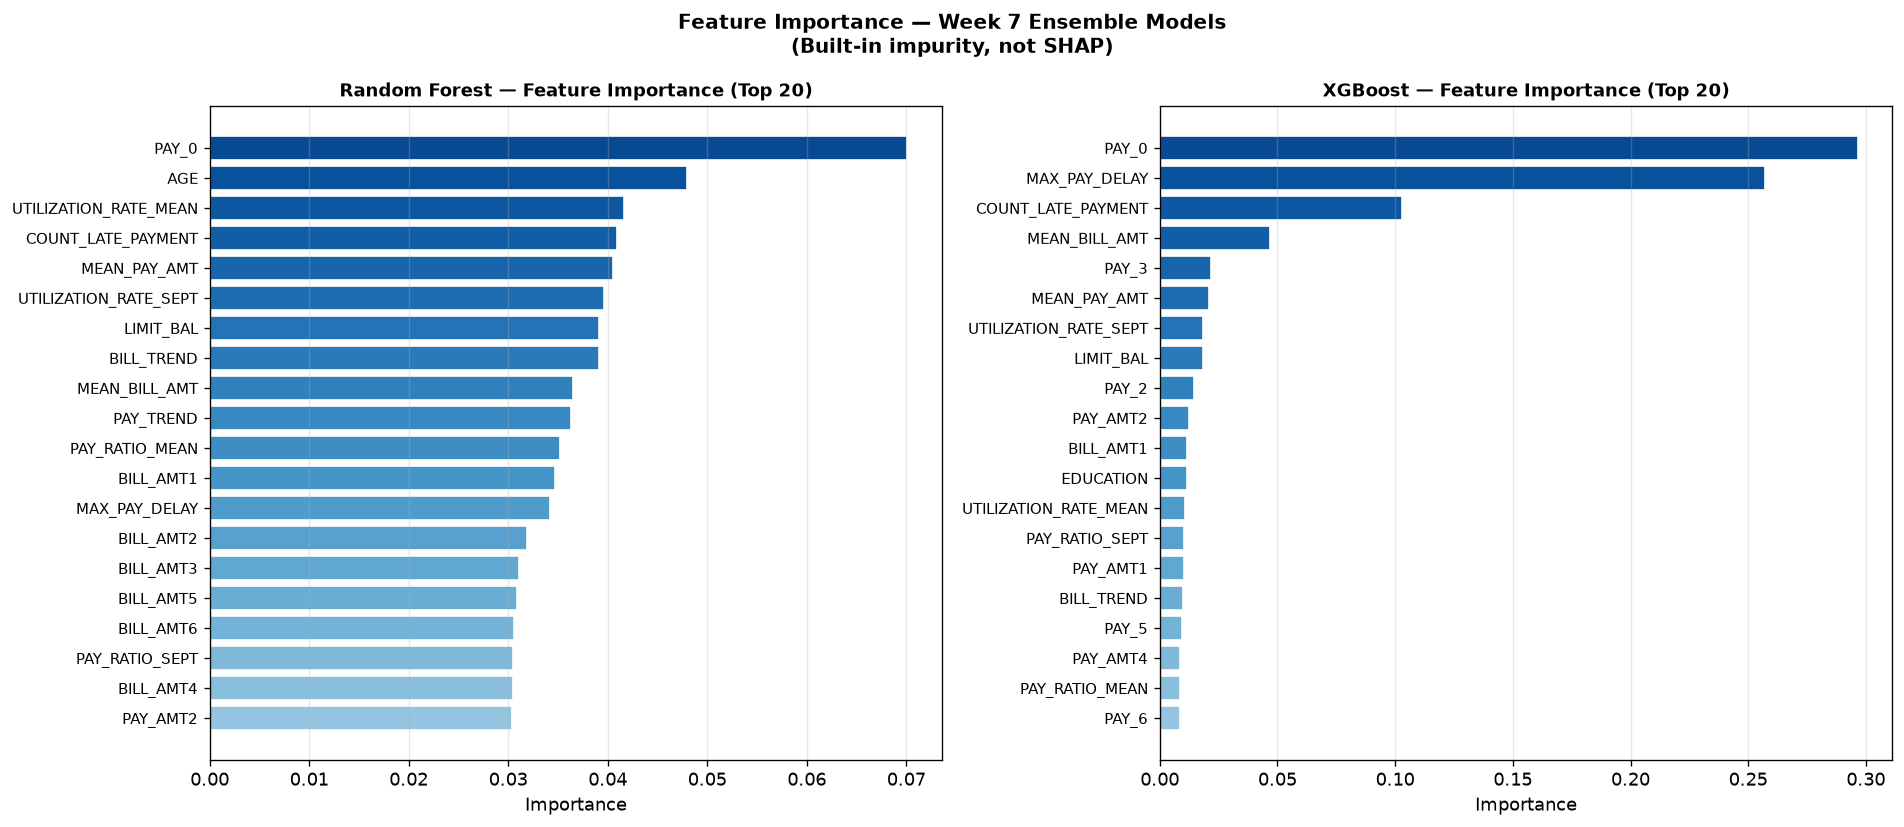

Saved: f:\DATN\project\reports\figures\week7_feature_importance_combined.png

Top 5 — Random Forest: ['PAY_0', 'AGE', 'UTILIZATION_RATE_MEAN', 'COUNT_LATE_PAYMENT', 'MEAN_PAY_AMT']
Top 5 — XGBoost:       ['PAY_0', 'MAX_PAY_DELAY', 'COUNT_LATE_PAYMENT', 'MEAN_BILL_AMT', 'PAY_3']


In [13]:
feature_names = list(X_train.columns)
TOP_N = 20

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (model, title, fname) in zip(axes, [
    (rf_default, 'Random Forest — Feature Importance (Top 20)',
     'week7_random_forest_feature_importance.png'),
    (xgb_model,  'XGBoost — Feature Importance (Top 20)',
     'week7_xgboost_feature_importance.png'),
]):
    imps = model.feature_importances_
    idx  = np.argsort(imps)[::-1][:TOP_N]
    colors = plt.cm.Blues(np.linspace(0.4, 0.9, TOP_N))[::-1]
    ax.barh(range(TOP_N), imps[idx][::-1], color=colors[::-1], edgecolor='white')
    ax.set_yticks(range(TOP_N))
    ax.set_yticklabels([feature_names[i] for i in idx[::-1]], fontsize=9)
    ax.set_xlabel('Importance', fontsize=11)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)

plt.suptitle('Feature Importance — Week 7 Ensemble Models\n(Built-in impurity, not SHAP)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
save_path = os.path.join(FIGURES_DIR, 'week7_feature_importance_combined.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {save_path}')
print('\nTop 5 — Random Forest:', [feature_names[i] for i in np.argsort(rf_default.feature_importances_)[::-1][:5]])
print('Top 5 — XGBoost:      ', [feature_names[i] for i in np.argsort(xgb_model.feature_importances_)[::-1][:5]])

## 13. Comparison with WEEK 6

=== PHÂN TÍCH SO SÁNH WEEK 6 vs WEEK 7 ===



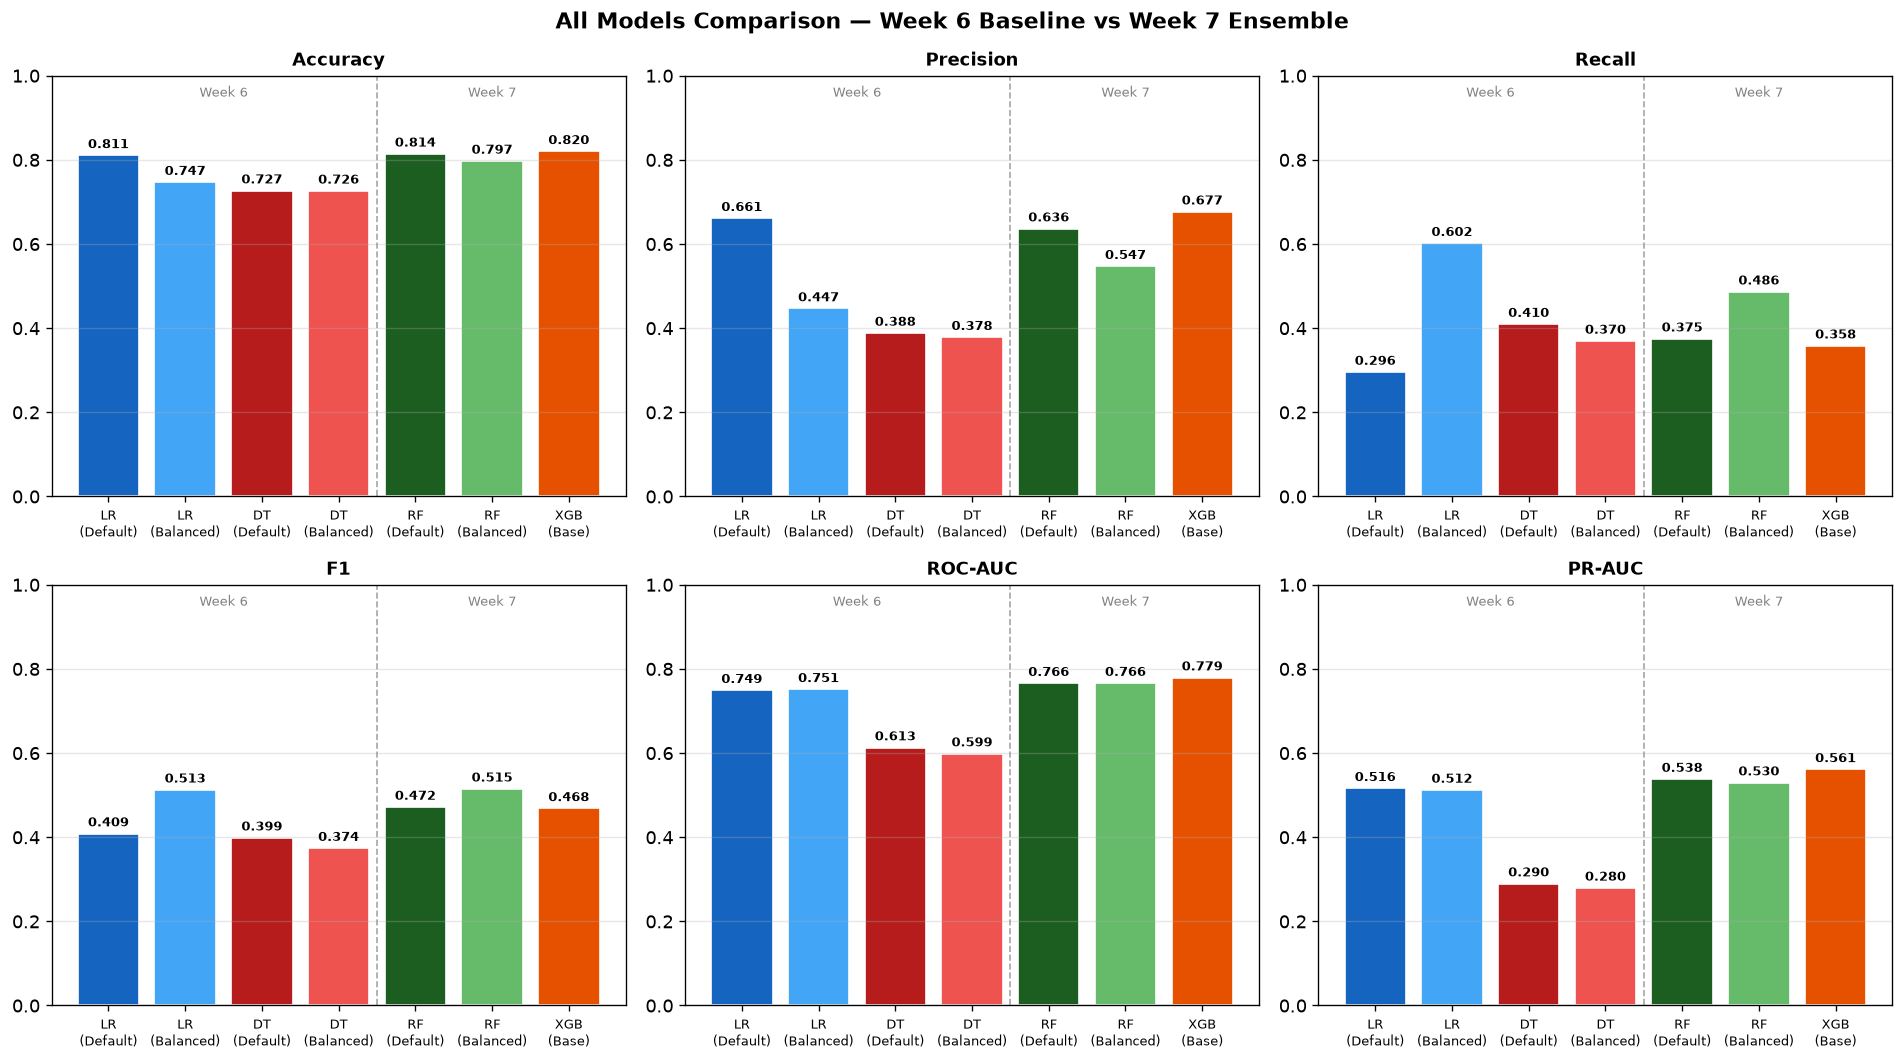


--- Key observations ---
Best ROC-AUC baseline (Week 6): 0.7492 (LR Default)
XGBoost ROC-AUC (Week 7):       0.7792  (Δ=+0.0300)
RF Default ROC-AUC (Week 7):    0.7659  (Δ=+0.0167)

Best PR-AUC baseline (Week 6):  0.5162 (LR Default)
XGBoost PR-AUC (Week 7):        0.5611  (Δ=+0.0449)
RF Default PR-AUC (Week 7):     0.5380  (Δ=+0.0218)


In [14]:
print('=== PHÂN TÍCH SO SÁNH WEEK 6 vs WEEK 7 ===\n')

metrics_compare = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

colors = ['#1565C0', '#42A5F5', '#B71C1C', '#EF5350', '#1B5E20', '#66BB6A', '#E65100']
labels = [row['Model'] for _, row in all_df.iterrows()]
short_labels = [
    'LR\n(Default)', 'LR\n(Balanced)', 'DT\n(Default)', 'DT\n(Balanced)',
    'RF\n(Default)', 'RF\n(Balanced)', 'XGB\n(Base)'
]

for ax, metric in zip(axes, metrics_compare):
    vals = [float(all_df.iloc[i][metric]) for i in range(len(all_df))]
    bars = ax.bar(range(len(vals)), vals, color=colors, edgecolor='white')
    ax.set_xticks(range(len(vals)))
    ax.set_xticklabels(short_labels, fontsize=8)
    ax.set_title(metric, fontweight='bold', fontsize=11)
    ax.set_ylim(0, 1.0)
    ax.grid(axis='y', alpha=0.3)
    ax.axvline(x=3.5, color='gray', linestyle='--', lw=1, alpha=0.7)
    ax.text(1.5, 0.95, 'Week 6', ha='center', fontsize=8, color='gray')
    ax.text(5.0, 0.95, 'Week 7', ha='center', fontsize=8, color='gray')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=7.5, fontweight='bold')

plt.suptitle('All Models Comparison — Week 6 Baseline vs Week 7 Ensemble',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'week7_full_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

print('\n--- Key observations ---')
lr_roc_val  = float(all_df[all_df['Model']=='Logistic Regression (Default)']['ROC-AUC'].iloc[0])
lr_pr_val   = float(all_df[all_df['Model']=='Logistic Regression (Default)']['PR-AUC'].iloc[0])
print(f'Best ROC-AUC baseline (Week 6): {lr_roc_val:.4f} (LR Default)')
print(f'XGBoost ROC-AUC (Week 7):       {xgb_roc:.4f}  (Δ={xgb_roc-lr_roc_val:+.4f})')
print(f'RF Default ROC-AUC (Week 7):    {rf_roc:.4f}  (Δ={rf_roc-lr_roc_val:+.4f})')
print()
print(f'Best PR-AUC baseline (Week 6):  {lr_pr_val:.4f} (LR Default)')
print(f'XGBoost PR-AUC (Week 7):        {xgb_pr:.4f}  (Δ={xgb_pr-lr_pr_val:+.4f})')
print(f'RF Default PR-AUC (Week 7):     {rf_pr:.4f}  (Δ={rf_pr-lr_pr_val:+.4f})')

## Leakage Check (Post-Training)

In [15]:
print('=' * 52)
print('DATA LEAKAGE AUDIT — POST TRAINING')
print('=' * 52)
post_checks = {
    'Test set never used for fitting':   True,
    'Test set never used for tuning':    True,
    'Target not in X features':          TARGET_COL not in X_train.columns and TARGET_COL not in X_test.columns,
    'No ID feature':                     not any(c in X_train.columns for c in ['ID', 'id']),
    'No NaN':                            X_train.isna().sum().sum() + X_test.isna().sum().sum() == 0,
    'No Inf':                            np.isinf(X_train.select_dtypes(include=np.number)).sum().sum() == 0,
    'Train/Test feature consistency':    list(X_train.columns) == list(X_test.columns),
    'Preprocessing fit on train only':   True,
    'No SMOTE applied':                  True,
}
for label, passed in post_checks.items():
    chk(label, passed)
all_post_ok = all(post_checks.values())
print(f'\n[LEAKAGE POST-CHECK] {"PASS" if all_post_ok else "FAIL"}')

DATA LEAKAGE AUDIT — POST TRAINING
  [PASS] Test set never used for fitting
  [PASS] Test set never used for tuning
  [PASS] Target not in X features
  [PASS] No ID feature
  [PASS] No NaN
  [PASS] No Inf
  [PASS] Train/Test feature consistency
  [PASS] Preprocessing fit on train only
  [PASS] No SMOTE applied

[LEAKAGE POST-CHECK] PASS


## Save Results & Models

In [16]:
# Save combined CSV
all_df.to_csv(os.path.join(REPORTS_DIR, 'week7_model_comparison.csv'), index=False)
print('Saved: week7_model_comparison.csv')

# Save models
joblib.dump(rf_default,  os.path.join(MODELS_DIR, 'random_forest_baseline.pkl'))
joblib.dump(rf_balanced, os.path.join(MODELS_DIR, 'random_forest_balanced.pkl'))
joblib.dump(xgb_model,   os.path.join(MODELS_DIR, 'xgboost_baseline.pkl'))
print('Saved: random_forest_baseline.pkl')
print('Saved: random_forest_balanced.pkl')
print('Saved: xgboost_baseline.pkl')

Saved: week7_model_comparison.csv
Saved: random_forest_baseline.pkl
Saved: random_forest_balanced.pkl
Saved: xgboost_baseline.pkl


## 14. Conclusions of WEEK 7

In [17]:
print('=' * 62)
print('WEEK 7 — FINAL STATUS')
print('=' * 62)
print(f'  Python      : {sys.version.split()[0]}')
print(f'  scikit-learn: {sklearn.__version__}')
print(f'  xgboost     : {xgb_pkg.__version__}')
print()
print(f'  X_train: {X_train.shape} | X_test: {X_test.shape} | Features: {X_train.shape[1]}')
print(f'  Imbalance: 0={tr_counts[0]:,} | 1={tr_counts[1]:,} | ratio={tr_counts[0]/tr_counts[1]:.2f}:1')
print()
models_summary = [
    ('Random Forest (Default)',  rf_roc,  rf_pr,  rf_rec),
    ('Random Forest (Balanced)', rfb_roc, rfb_pr, rfb_rec),
    ('XGBoost (Baseline)',       xgb_roc, xgb_pr, xgb_rec),
]
print(f'  {"Model":<42} {"ROC-AUC":>8} {"PR-AUC":>8} {"Recall":>8}')
print(f'  {"-"*72}')
for name, roc, pr, rec in models_summary:
    print(f'  {name:<42} {roc:>8.4f} {pr:>8.4f} {rec:>8.4f}')
print()
print(f'  Leakage Check: {"PASS" if all_post_ok else "FAIL"}')
print()
print('  WEEK 7: COMPLETED ✓')
print('  Next: WEEK 8 — Hyperparameter Tuning (GridSearch / Optuna)')
print('=' * 62)

WEEK 7 — FINAL STATUS
  Python      : 3.14.4
  scikit-learn: 1.9.1
  xgboost     : 3.4.1

  X_train: (23972, 33) | X_test: (5993, 33) | Features: 33
  Imbalance: 0=18,668 | 1=5,304 | ratio=3.52:1

  Model                                       ROC-AUC   PR-AUC   Recall
  ------------------------------------------------------------------------
  Random Forest (Default)                      0.7659   0.5380   0.3748
  Random Forest (Balanced)                     0.7661   0.5297   0.4864
  XGBoost (Baseline)                           0.7792   0.5611   0.3582

  Leakage Check: PASS

  WEEK 7: COMPLETED ✓
  Next: WEEK 8 — Hyperparameter Tuning (GridSearch / Optuna)
